# Natural language processing and large language models

*Data Science and AI, Module 8. Slides: `Module_8.pdf`.*

Keep the slides open on the right. Every heading below carries the slide
numbers it goes with, so the two stay in step.

Natural language processing (NLP) is about getting a computer to do useful
work with text people wrote for other people. By the end of this notebook
you will have taken text apart with patterns, pulled it off a web page,
cleaned it, scored its mood, trained a model to sort it, and looked inside
the dice roll that makes a large language model (LLM) write.

**How each section works.** A question comes first. Make a guess out loud or
in the chat before the cell runs. Then run it and compare.

**Four kinds of text.**

- Small **made-up** examples, always labelled as made up.
- The **Titanic passenger list** from the ML challenge (`titanic_train.csv`),
  because the names hide something useful.
- **2,000 film reviews**, 1,000 positive and 1,000 negative, from Bo Pang and
  Lillian Lee, "A Sentimental Education", Proceedings of the ACL, 2004
  (polarity dataset v2.0, distributed with NLTK with the authors'
  permission).
- One live web page, `books.toscrape.com`, a site built for scraping
  practice. Its prices are random and mean nothing.

The notebook is in six parts, one per section of the deck. Each part loads
what it needs, so you can start at any part.

## Before the first session: one-off downloads

The `dsai` environment already has NLTK and spaCy. Both need some data
files the first time. Run the cell below once; afterwards it takes a second.

spaCy's English model is installed from a terminal, not from Python. If the
cell says it is missing, open the Anaconda Prompt (Windows) or Terminal
(Mac), run `conda activate dsai`, then the command the cell prints.

In [1]:
import nltk
import spacy

# Each download is skipped quickly if it is already on this computer.
nltk.download("vader_lexicon", quiet=True)   # word list for sentiment (Part 4)
nltk.download("stopwords", quiet=True)       # common words (Part 3)
nltk.download("wordnet", quiet=True)         # dictionary for lemmas (Part 3)
nltk.download("movie_reviews", quiet=True)   # the 2,000 film reviews

print("nltk", nltk.__version__)
print("spacy", spacy.__version__)

if spacy.util.is_package("en_core_web_sm"):
    print("spaCy English model: installed")
else:
    print("spaCy English model missing. Run this once in a terminal:")
    print("    python -m spacy download en_core_web_sm")    

nltk 3.10.2
spacy 3.8.14
spaCy English model: installed


# Part 3: slides 24-37

Working with text: tokens, stop words, stems and lemmas, grammar, names,
and words as vectors.

In [2]:
import numpy as np
import pandas as pd
import spacy
from nltk.corpus import stopwords, movie_reviews
from nltk.stem import PorterStemmer, WordNetLemmatizer

nlp = spacy.load("en_core_web_sm")   # spaCy's small English model

In [3]:
nltk_stop_words = set(stopwords.words("english"))
spacy_stop_words = nlp.Defaults.stop_words

print("NLTK list: ", len(nltk_stop_words), "words")
print("spaCy list:", len(spacy_stop_words), "words")
print("'not' in NLTK list: ", "not" in nltk_stop_words)
print("'not' in spaCy list:", "not" in spacy_stop_words)

NLTK list:  198 words
spaCy list: 326 words
'not' in NLTK list:  True
'not' in spaCy list: True


In [4]:
def remove_stop_words(text):
    kept = []
    for token in nlp(text):
        if token.text.lower() not in nltk_stop_words:
            kept.append(token.text)
    return kept


print(remove_stop_words("flights to Melbourne"))
print(remove_stop_words("flights from Melbourne"))
print(remove_stop_words("this film is not good"))

['flights', 'Melbourne']
['flights', 'Melbourne']
['film', 'good']


In [5]:
def remove_stop_words_spacy(text):
    # empty list to collect the words we keep
    kept = []

    # spaCy splits the text into tokens
    doc = nlp(text)

    # look at each token one at a time
    for token in doc:
        # is_stop is True if spaCy thinks this is a stop word
        if not token.is_stop:
            # not a stop word, so keep it
            kept.append(token.text)

    return kept


print(remove_stop_words_spacy("flights to Melbourne"))
print(remove_stop_words_spacy("flights from Melbourne"))
print(remove_stop_words_spacy("this film is not good"))

['flights', 'Melbourne']
['flights', 'Melbourne']
['film', 'good']


Two different trips became the same two words, and a negative review now
reads "film good". Stop-word removal saves space in a search index, but for
anything about meaning or mood, test whether it helps before using it.
Part 5 tests it on the reviews.

In [6]:
# words that change meaning, so we do not want them removed
words_to_keep = ["not", "no", "never", "to", "from"]

# take each one off spaCy's stop-word list
for word in words_to_keep:
    nlp.vocab[word].is_stop = False

In [7]:
# the review we want to clean
review = "this film is not good"
# split the review into tokens again
doc = nlp(review)

# keep only the tokens that are not stop words
print(remove_stop_words_spacy("this film is not good"))

['film', 'not', 'good']


## Slide 28: stemming and lemmatisation

Both bring word forms together. A **stemmer** chops endings by rule; the
result need not be a real word. A **lemmatiser** looks words up and returns
the dictionary form (the **lemma**), and it works better when told the part
of speech.

Before I run this: what will the stemmer make of "studies"?

In [8]:
stemmer = PorterStemmer()
lemmatiser = WordNetLemmatizer()

rows = []
for word in ["organise", "organises", "organising", "studies", "running", "ran", "better"]:
    rows.append({
        "word": word,
        "stem": stemmer.stem(word),
        "lemma (as noun)": lemmatiser.lemmatize(word),
        "lemma (as verb)": lemmatiser.lemmatize(word, pos="v"),
        "lemma (as adjective)": lemmatiser.lemmatize(word, pos="a"),
    })

print(pd.DataFrame(rows))

         word     stem lemma (as noun) lemma (as verb) lemma (as adjective)
0    organise  organis        organise        organise             organise
1   organises  organis       organises        organise            organises
2  organising  organis      organising        organise           organising
3     studies    studi           study           study              studies
4     running      run         running             run              running
5         ran      ran             ran             run                  ran
6      better   better          better          better                 good


Read down the columns:

- the stemmer turns all three "organise" forms into `organis`, which is not
  a word but is the same for all three, and that is all a search engine
  needs;
- the lemmatiser assumes a noun unless told otherwise, so `running` stays
  `running` until it is told it is a verb;
- `better` becomes `good` only when the lemmatiser is told it is an
  adjective.

spaCy works out the part of speech itself, from the sentence, and lemmatises
with it. Its guesses are not always the ones you would make.

In [9]:
for token in nlp("She studies better songs and was running and organising"):
    print(f"{token.text:<11} lemma {token.lemma_:<9} part of speech {token.pos_}")

She         lemma she       part of speech PRON
studies     lemma study     part of speech VERB
better      lemma well      part of speech ADJ
songs       lemma song      part of speech NOUN
and         lemma and       part of speech CCONJ
was         lemma be        part of speech AUX
running     lemma run       part of speech VERB
and         lemma and       part of speech CCONJ
organising  lemma organise  part of speech VERB


spaCy's small model gives `better` the lemma `well`, not `good`. Both
"good" and "well" have "better" as their comparative, and the model picked
one. Treat lemmas from any tool as a useful simplification, not as the
truth.

## Slides 29-30: parts of speech

A part-of-speech (POS) tagger labels each token with its job: noun, verb,
adjective and so on. spaCy uses the Universal Dependencies tag set, so
`spacy.explain` can spell each tag out.

Before I run this: in the slide 30 sentence, what job is "over" doing?

In [10]:
sentence = nlp("The brown fox is quick, and he is jumping over the lazy dog.")

rows = []
for token in sentence:
    rows.append({"token": token.text, "tag": token.pos_, "meaning": spacy.explain(token.pos_)})

print(pd.DataFrame(rows))

      token    tag                   meaning
0       The    DET                determiner
1     brown    ADJ                 adjective
2       fox   NOUN                      noun
3        is    AUX                 auxiliary
4     quick    ADJ                 adjective
5         ,  PUNCT               punctuation
6       and  CCONJ  coordinating conjunction
7        he   PRON                   pronoun
8        is    AUX                 auxiliary
9   jumping   VERB                      verb
10     over    ADP                adposition
11      the    DET                determiner
12     lazy    ADJ                 adjective
13      dog   NOUN                      noun
14        .  PUNCT               punctuation


"Over" links "jumping" to "the lazy dog", so spaCy calls it an
**adposition** (`ADP`), the umbrella term for prepositions. Both copies of
"is" are tagged `AUX`, an auxiliary verb: the first links "fox" to "quick",
the second helps "jumping". The tag for "and" is `CCONJ`, a coordinating
conjunction. "Over" can be an adverb in other sentences ("the game is
over"), which is the whole point of slide 30: the tag depends on the
sentence, not the word.

## Slide 29: parsing

A **parser** finds who did what to whom. Each token points to the word it
depends on (its *head*) and gets a relation label.

In [11]:
for token in nlp("The brown fox chased the lazy dog."):
    print(f"{token.text:<7} {token.dep_:<6} -> {token.head.text:<7} ({spacy.explain(token.dep_)})")
#token.dep_      │ its role in the sentence
#token.head.text │ the word it points to (its head)


The     det    -> fox     (determiner)
brown   amod   -> fox     (adjectival modifier)
fox     nsubj  -> chased  (nominal subject)
chased  ROOT   -> chased  (root)
the     det    -> dog     (determiner)
lazy    amod   -> dog     (adjectival modifier)
dog     dobj   -> chased  (direct object)
.       punct  -> chased  (punctuation)


"fox" is the **nominal subject** of "chased", "dog" is its **direct
object**, and "chased" is the root of the sentence. That is subject, verb
and object, found automatically.

## Slides 31-32: named entities

Named-entity recognition (NER) finds names of people, places,
organisations, dates and amounts, and labels each.

Before I run this: will spaCy's small model find the stardate, and what will
it make of "Rear Admiral"?

In [12]:
captain = nlp("Captain Jean-Luc Picard took command of the ship on stardate 41148 at the order of Rear Admiral Norah Satie.")

for entity in captain.ents:
    print(f"{entity.text:<16} {entity.label_:<7} {spacy.explain(entity.label_)}")

Jean-Luc Picard  PERSON  People, including fictional
41148            DATE    Absolute or relative dates or periods
Rear Admiral     ORG     Companies, agencies, institutions, etc.
Norah Satie      PERSON  People, including fictional


The two people are found, multi-word names and all, and `41148` is called a
date. "Rear Admiral" is labelled an
organisation, which is wrong: it is a rank. This is the small model; larger
models make fewer mistakes, never none.

Try it on a **made-up** local sentence.

In [13]:
local = nlp("Aroha Smith flew from Auckland to Wellington on Friday to meet the Fonterra board.")

for entity in local.ents:
    print(f"{entity.text:<14} {entity.label_:<7} {spacy.explain(entity.label_)}")

Aroha Smith    PERSON  People, including fictional
Auckland       GPE     Countries, cities, states
Wellington     GPE     Countries, cities, states
Friday         DATE    Absolute or relative dates or periods
Fonterra       PERSON  People, including fictional


The person, the two cities and the day are right. Fonterra, a company, is
labelled a person. Test any NER model on text from
your own setting before relying on it.

## Slides 33-34: NLTK and spaCy

Both are free Python libraries; this notebook has used both.

- **NLTK** is a toolbox with many alternative tools and teaching corpora,
  including the film reviews. We used its stop words, stemmer, lemmatiser
  and, in Part 4, its sentiment scorer.
- **spaCy** gives one pipeline per language: `nlp(text)` returns tokens,
  lemmas, tags, parse and entities in one go, quickly.

## Slides 35-36: words as vectors

To a computer, "terrible" and "awful" are different strings with nothing
in common. A **one-hot** vector makes that explicit: one column per word,
a 1 in the word's own column, zeros elsewhere. Every pair of different
words is equally unrelated.

An **embedding** gives each word a short list of numbers instead, chosen so
that words used in similar contexts get similar lists. Word2vec learns them
with a small neural network.

In [14]:
import numpy as np

# one column per word, a 1 in the word's own column
terrible = np.array([1, 0, 0])
awful    = np.array([0, 1, 0])
great    = np.array([0, 0, 1])

# multiply matching positions and add them up (the dot product)
print(terrible @ awful)
print(terrible @ great)

0
0


In [15]:
# each word gets 2 numbers: [how positive, how strong]
terrible = np.array([-0.9, 0.6])
awful    = np.array([-0.7, 0.9])
great    = np.array([ 0.9, 0.8])
okay     = np.array([ 0.5, 0.1])

#"terrible is very negative and fairly strong." These numbers are chosen by hand for now.

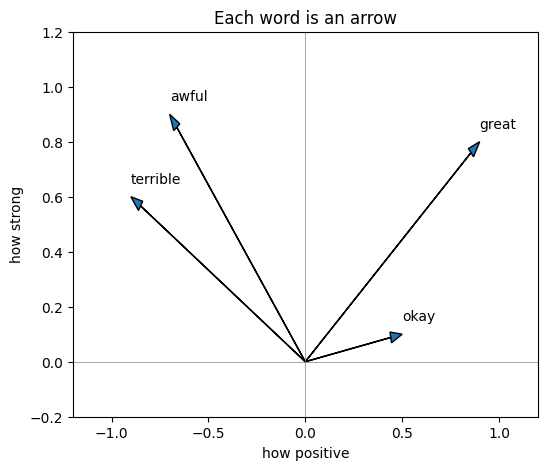

In [16]:
import matplotlib.pyplot as plt

# put the words in a dictionary so we can loop over them
words = {"terrible": terrible, "awful": awful, "great": great, "okay": okay}

fig, ax = plt.subplots(figsize=(6, 5))

# draw one arrow per word, from (0, 0) to the word's two numbers
for name in words:
    vector = words[name]
    ax.arrow(0, 0, vector[0], vector[1], head_width=0.04, length_includes_head=True)
    ax.text(vector[0], vector[1] + 0.05, name)

# draw the axes through zero
ax.axhline(0, color="grey", linewidth=0.5)
ax.axvline(0, color="grey", linewidth=0.5)

# label the plot
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-0.2, 1.2)
ax.set_xlabel("how positive")
ax.set_ylabel("how strong")
ax.set_title("Each word is an arrow")
plt.show()

### The plot shows "terrible" and "awful" pointing up-left together, "great" up-right, and "okay" low to the right. 
## "Which two arrows point the same way?"

Closeness is measured with **cosine similarity**: 1 for vectors pointing the
same way, 0 for unrelated directions.

$$\text{similarity}(a, b) = \frac{a \cdot b}{\lVert a \rVert \, \lVert b \rVert}$$

In [17]:
# top of the formula: the dot product
top = terrible @ awful

# bottom of the formula: the length of each arrow
length_a = np.linalg.norm(terrible)
length_b = np.linalg.norm(awful)

# divide top by bottom
similarity = top / (length_a * length_b)

print("top:", round(top, 2))
print("length of terrible:", round(length_a, 2))
print("length of awful:", round(length_b, 2))
print("similarity:", round(similarity, 2))

top: 1.17
length of terrible: 1.08
length of awful: 1.14
similarity: 0.95


In [18]:
# wrap it in a function and compare
def cosine_similarity(a, b):
    # dot product on top
    top = a @ b
    # lengths multiplied on the bottom
    bottom = np.linalg.norm(a) * np.linalg.norm(b)
    return top / bottom


print("terrible vs awful:", round(cosine_similarity(terrible, awful), 2))
print("terrible vs great:", round(cosine_similarity(terrible, great), 2))
print("great vs okay:    ", round(cosine_similarity(great, okay), 2))
print("terrible vs okay: ", round(cosine_similarity(terrible, okay), 2))

terrible vs awful: 0.95
terrible vs great: -0.25
great vs okay:     0.86
terrible vs okay:  -0.71


In [19]:
# a phrase is the sum of its words
# made-up vectors for four words
red   = np.array([1.0, 2.0])
white = np.array([2.0, 1.5])
van   = np.array([3.0, 0.3])
car   = np.array([3.0, 0.1])

# a phrase = add the word vectors together
red_van   = red + van
white_car = white + car

print("red van:  ", red_van)
print("white car:", white_car)
print("red van vs white car:", round(cosine_similarity(red_van, white_car), 2))

red van:   [4.  2.3]
white car: [5.  1.6]
red van vs white car: 0.98


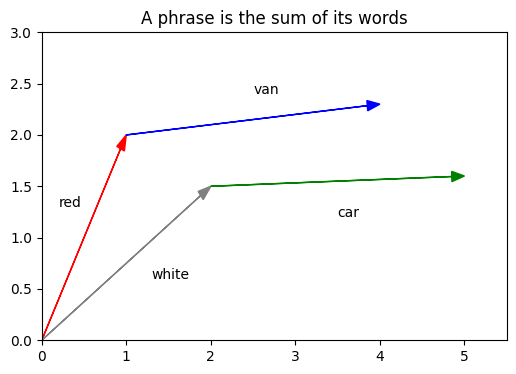

In [20]:
fig, ax = plt.subplots(figsize=(6, 4))

# red, then van starting where red ends
ax.arrow(0, 0, red[0], red[1], color="red", head_width=0.1, length_includes_head=True)
ax.arrow(red[0], red[1], van[0], van[1], color="blue", head_width=0.1, length_includes_head=True)

# white, then car starting where white ends
ax.arrow(0, 0, white[0], white[1], color="grey", head_width=0.1, length_includes_head=True)
ax.arrow(white[0], white[1], car[0], car[1], color="green", head_width=0.1, length_includes_head=True)

# labels
ax.text(0.2, 1.3, "red")
ax.text(2.5, 2.4, "van")
ax.text(1.3, 0.6, "white")
ax.text(3.5, 1.2, "car")

ax.set_xlim(0, 5.5)
ax.set_ylim(0, 3)
ax.set_title("A phrase is the sum of its words")
plt.show()

In real life, nobody types the numbers in. They are learned from lots of text, from one simple rule: words that keep the same company get similar numbers.

In [21]:
import sys

# sys.executable is this notebook's own Python, so the model lands in the right environment
!{sys.executable} -m spacy download en_core_web_md

  Using cached en_core_web_md-3.8.0-py3-none-any.whl (33.5 MB)


✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_md')


In [22]:
# Download someone else's (what people actually do)

# one-off install, in the terminal:
#! python -m spacy download en_core_web_md

import spacy

# load the medium model (the small one has no word vectors)
nlp = spacy.load("en_core_web_md")
#nlp = spacy.load("en_core_web_sm")

# look up the word's vector
terrible = nlp("terrible")

# how many numbers does a word get?
print(terrible.vector.shape)

# the first five of them
print(terrible.vector[:5])

# spaCy has cosine similarity built in
print(nlp("terrible").similarity(nlp("awful")))
print(nlp("terrible").similarity(nlp("great")))

(300,)
[-0.71302    0.090462   0.36503   -0.14336    0.0035745]
0.7384125590324402
0.37891605496406555


These are *static* embeddings: "bat" gets one vector whether it is the
animal or the cricket bat. The models behind LLMs produce **contextual**
embeddings, where the vector for a word depends on the sentence around it.

## Slide 37: Lab 8.2

Lab 8.2 practises NLTK and spaCy.